# <FONT SIZE=5 COLOR="#88E788"> Proyecto Representación</FONT>
Representación y Solución Automática de Problemas  
Escuela de Ingeniería, Ciencia y Tecnología              
Matemáticas aplicadas y ciencias de la computación
Universidad del Rosario     
Daniel José Morales y Juan Esteban Torres




## <FONT SIZE=5 COLOR="#88E788"> 1. Descripción del Entorno, Reglas y Formalización Matemática</FONT>

El juego que decidimos desarrollar fue Snake, el cual se desarrolla en una cuadrícula de $10 \times 10$ con celdas $(x, y) \in \{0, \dots, 9\}^2$ donde a simple vista el escenario es estocástico debido a que el agente desconoce dónde aparecerá la siguiente fruta hasta comer la actual, sin embargo, una vez que una nueva fruta aparece, el escenario se tranforma en un problema determinista, por esto mismo, buscamos a que el proyecto descompone el escenario en una secuencia de subproblemas deterministas resueltos por un agente basado en modelo y basado en objetivos.

|   |  |
| :--- | :--- |
| ✓ Completamente observable |  Parcialmente observable |
| ✓ Single-agent (Base) | ✓ Multi-agent (Variante) |
| ✓ Determinista (Micro) | ✓ Estocástico (Macro) |
|  Episódico | ✓ Secuencial |
| ✓ Estático (Por turnos) |  Dinámico |
| ✓ Discreto | Continuo |
| ✓ Conocido (*Model-Based*) | Desconocido (*Model-Free*) |

### <FONT SIZE=5 COLOR="#88E788"> Formalización del Problema y Caracterización según la Guía</FONT>

* **Estados ($S$):** En cada instante de tiempo $t$, el estado del entorno está definido por la tupla $s = (C, f)$, donde $C = (c_1, c_2, \dots, c_L)$ es la secuencia ordenada de coordenadas $(x, y) \in \{0, \dots, N-1\}^2$ que reresentan el cuerpo de la serpiente con $c_1$ como la cabeza, $c_L$ la cola y una longitud definida como $L = |C|$. $f \in \{0, \dots, N-1\}^2 \setminus C$ es la poscicion de la fruta actual y en dado caso que tengamos obstaculos fijos.
* **Acciones ($A$):** El conjunto de decisiones posibles lo definimos como: $\mathcal{A} = \{\text{norte}, \text{sur}, \text{este}, \text{oeste}\}$, con vectores de desplazamiento $\delta(a) \in \{(0,1), (0,-1), (1,0), (-1,0)\}$. Una acción $a \in \mathcal{A}$ es aplicable en el estado $s$ si la nueva posición de la cabeza $h' = c_1 + \delta(a)$ permanece dentro de los límites del tablero (o se envuelve modularmente en la variante toroidal) y no colisiona con los segmentos $c_1, \dots, c_{L-1}$ ni con obstáculos. La casilla de la cola $c_L$ sí es válida para $L > 2$ porque se desplaza en el mismo turno, y para $L \ge 2$ se excluye el giro de $180^\circ$ hacia el cuello $c_2$, dejando un factor de ramificación máximo $b \le 3$.
* **Función de Transición ($T$ — Dinámica Conocida / *Model-Based*):** Dada una acción aplicable $a$ que lleva la cabeza a $h' = c_1 + \delta(a)$, el entorno evoluciona mediante dos casos:
  1. *Desplazamiento sin comer ($h' \neq f$):* El cuerpo avanza una celda y la cola libera su casilla anterior, resultando en $C' = (h', c_1, \dots, c_{L-1})$ con la misma fruta $f' = f$.
  2. *Crecimiento al comer ($h' = f$):* La serpiente incrementa su longitud en una unidad sin desplazar la cola, resultando en $C' = (h', c_1, \dots, c_L)$, y aparece una nueva fruta $f'$ elegida con distribución aleatoria uniforme entre las celdas libres (o colocada por el oponente Minimax en la variante adversaria).
  La dinámica física del cuerpo es **completamente conocida (*Model-Based*)**, lo que permite al agente simular trayectorias exactas durante la planeación.
* **Función de Pérdida por Paso $c(s,a,s')$ y Función de Recompensa ($R$):**
  * *Costo / Pérdida de transición (Nivel Micro):* Cada movimiento en el árbol de búsqueda tiene un costo positivo que penaliza tanto el número de pasos como el riesgo de encierro local alrededor de la nueva cabeza $h'$:
    $$c(s, a, s') = 1 + \lambda \cdot r(h'), \qquad r(h') = \frac{\text{vecinos bloqueados}(h')}{3} \in [0, 1]$$
    donde $\text{vecinos bloqueados}(h') \in \{0, 1, 2, 3\}$ cuenta cuántas de las 3 direcciones futuras desde $h'$ están obstruidas por el cuerpo, muros o bordes del tablero, y $\lambda \ge 0$ pondera la aversión al riesgo.
  * *Señal de Recompensa Inmediata y Acumulada (Nivel Macro):* En cada turno de la partida el entorno entrega una recompensa inmediata $R(s, a, s')$ definida por el balance entre ganancias y pérdidas:
    $$R(s, a, s') = \begin{cases} +1000 - c(s,a,s') & \text{si } h' = f \text{ y } L' = N^2 - |\text{obstáculos}| \text{ (Victoria)} \\ +100 - c(s,a,s') & \text{si } h' = f \text{ y } L' < N^2 - |\text{obstáculos}| \text{ (Fruta comida)} \\ -100 - c(s,a,s') & \text{si } s' \text{ queda encerrado sin acciones aplicables (Derrota)} \\ -c(s,a,s') & \text{en desplazamiento normal ($h' \neq f$)} \end{cases}$$
    La **recompensa acumulada** a lo largo del episodio ($G = \sum_{t} R_t$) se relaciona directamente con los objetivos del proyecto: maximizar $G$ exige maximizar el número de frutas consumidas mientras se minimiza la cantidad de pasos y el riesgo de auto-encierro.
* **Objetivo del Agente y Estados Terminales:**
  * *Objetivo por subproblema (Micro):* Encontrar un camino de acciones que lleve la cabeza hasta la fruta actual ($c_1 = f$) minimizando el costo acumulado $g(n) = \sum c(s_i, a_i, s_{i+1})$, sujeto a la restricción de seguridad de que en el estado final simulado exista al menos una ruta válida desde la cabeza hasta la cola $c_L$.
  * *Objetivo global (Macro):* Maximizar la longitud final alcanzada $L_{\text{final}}$ (y la recompensa acumulada $G$) hasta lograr llenar el tablero.
  * *Estados terminales:* Un episodio termina cuando se alcanza cualquiera de los siguientes tres estados: **(1) Victoria**, al llenar todas las celdas disponibles del tablero ($L = 100$ en la versión base $10\times 10$); **(2) Encierro o colisión**, cuando desde el estado actual no existe ninguna acción aplicable ($\mathcal{A}(s) = \emptyset$); o **(3) Límite de pasos sin comer**, cuando transcurren $k_{\max} = 200$ turnos consecutivos sin consumir una fruta.


In [1]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# En Google Colab se monta Drive; en Jupyter / VS Code local se usa la carpeta del notebook
try:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA = Path('/content/drive/MyDrive/Proyecto Representación')
except ImportError:
    CARPETA = Path.cwd()
sys.path.insert(0, str(CARPETA))

import ambientes, busqueda, agentes, utils, interfaz
importlib.reload(ambientes)
importlib.reload(busqueda)
importlib.reload(agentes)
importlib.reload(utils)
importlib.reload(interfaz)

from ambientes import EstadoSnake, SubproblemaSnake, Snake, SnakeJuegoAdversario
from busqueda import (
    anchura, profundidad, dijkstra, avara, a_estrella, busqueda_haz,
    heuristica_manhattan, heuristica_euclidea, heuristica_riesgo,
    solucion, comparar_algoritmos_en_instancia
)
from agentes import AgenteSnake, AgenteFrutaAdversaria
from utils import (
    Episode, Plot, Experiment, EnvfromGameAndPl2, ExperimentEspacios,
    ejecutar_benchmark_completo, graficar_resultados_benchmark
)
from interfaz import lanzar_aplicacion_snake
print("Módulos cargados correctamente.")

Módulos cargados correctamente.


---
## 2. Aplicación Gráfica Interactiva: **SnakeLab Studio**
*(Nota: Interfaz gráfica interactiva desarrollada con apoyo de IA generativa según lo autorizado en las instrucciones del proyecto).*

Al ejecutar la celda siguiente, `interfaz.py` levanta un pequeño servidor dentro del kernel y muestra un enlace que abre **SnakeLab Studio** en otra pestaña del navegador (en Colab mediante `google.colab.output`; en Jupyter local en `http://localhost:8050`). La página (`web/index.html`, `web/app.js`, `web/estilos.css`) llama directamente a `ambientes.py`, `busqueda.py` y `agentes.py`, y reúne en **5 pestañas** todos los elementos visuales e interactivos requeridos:
1. **Búsqueda paso a paso:** editor de instancias (aleatorias o dibujadas sobre el tablero) y controles de reproducción que muestran nodos expandidos, frontera, nodo actual y $f(n) = g(n) + h(n)$ en cada iteración.
2. **Comparar algoritmos:** ejecuta los 6 algoritmos y las 3 heurísticas sobre la misma instancia y grafica sus métricas (nodos expandidos y generados, frontera máxima, tiempo y costo).
3. **Partida completa:** reproduce una partida entera de `AgenteSnake` mostrando cuándo actúa el chequeo de seguridad hacia la cola.
4. **Juega contra la IA:** permite jugar manualmente y comparar tu puntaje contra el agente.
5. **Resultados 100 semillas:** resume el CSV del experimento de la Sección 5.

In [2]:
# Lanzar la aplicación gráfica interactiva completa
lanzar_aplicacion_snake()


---
## 3. Ejemplificación de una Instancia del Entorno, sus Métodos y Atributos
De acuerdo con los aspectos técnicos de la guía (Sección 2.3), se instancia explícitamente el entorno y el espacio de estados mostrando sus atributos y métodos principales (`estado_inicial`, `acciones_aplicables`, `transicion`, `test_objetivo`, `costo`, `codigo` y `render`).


1. Estado inicial s=(C,f) : EstadoSnake(cabeza=(5, 5), L=1, fruta=(8, 0))
2. Código único codigo(s) : 5-5
3. Acciones aplicables    : ['sur', 'oeste']
4. ¿Es estado objetivo?   : False
5. Transición con 'sur'   : EstadoSnake(cabeza=(5, 4), L=1, fruta=(8, 0))
6. Costo/Pérdida paso     : 1.000
7. Heurística Manhattan   : 8.000
8. Heurística Euclídea    : 5.831
9. Solución con a_estrella: ['sur', 'sur', 'sur', 'sur', 'este', 'este', 'sur', 'este']


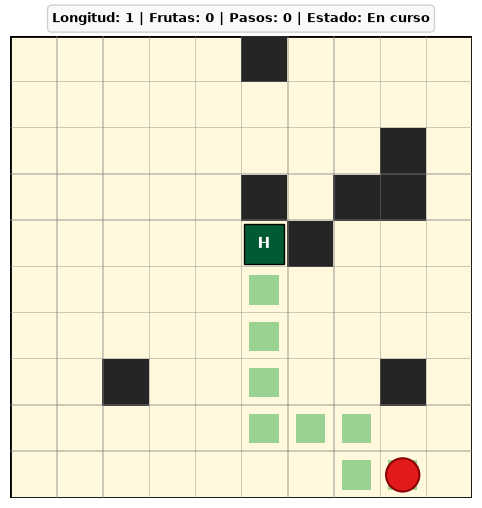

<Axes: title={'center': 'Longitud: 1 | Frutas: 0 | Pasos: 0 | Estado: En curso'}>

In [3]:
# Creación de una instancia y demostración de sus métodos y atributos
env_ejemplo = Snake(tamano=10, semilla=7, num_obstaculos=8, lambda_riesgo=0.5)
est_ejemplo = env_ejemplo.reset(semilla=7)
prob_ejemplo = SubproblemaSnake(estado_inicial=est_ejemplo, lambda_riesgo=0.5)

print("1. Estado inicial s=(C,f) :", prob_ejemplo.estado_inicial)
print("2. Código único codigo(s) :", prob_ejemplo.codigo(est_ejemplo))
print("3. Acciones aplicables    :", prob_ejemplo.acciones_aplicables(est_ejemplo))
print("4. ¿Es estado objetivo?   :", prob_ejemplo.test_objetivo(est_ejemplo))

acc_muestra = prob_ejemplo.acciones_aplicables(est_ejemplo)[0]
est_trans = prob_ejemplo.transicion(est_ejemplo, acc_muestra)
print(f"5. Transición con '{acc_muestra}'   : {est_trans}")
print(f"6. Costo/Pérdida paso     : {prob_ejemplo.costo(est_ejemplo, acc_muestra):.3f}")
print(f"7. Heurística Manhattan   : {heuristica_manhattan(est_ejemplo):.3f}")
print(f"8. Heurística Euclídea    : {heuristica_euclidea(est_ejemplo):.3f}")

# Aplicación directa de los algoritmos del taller (busqueda.py)
nodo_astar = a_estrella(prob_ejemplo, heuristica_manhattan)
print("9. Solución con a_estrella:", solucion(nodo_astar))
env_ejemplo.render(camino=prob_ejemplo.ultimo_resultado.camino_celdas)


### 3.1 El entorno secuencial `Snake`: atributos y la función `step()`
El subproblema anterior es el nivel *micro* (un solo camino hasta la fruta). El entorno `Snake` es el nivel *macro*: guarda la partida completa y, en cada turno, `step(a)` devuelve exactamente la tupla $(s', R(s,a,s'), \text{done})$ con la recompensa $R$ definida en la Sección 1. A continuación se imprimen los atributos del entorno y del estado $s = (C, f)$, y se ejecuta `step()` a mano siguiendo el plan de `A*` hasta comer la primera fruta.

In [4]:
# Atributos del entorno Snake y del estado EstadoSnake s = (C, f)
env_demo = Snake(tamano=10, semilla=7, num_obstaculos=8, lambda_riesgo=0.5, k_max=200)
s = env_demo.reset(semilla=7)

print("Atributos del entorno Snake")
for nombre in ["tamano", "semilla", "toroidal", "num_obstaculos", "num_frutas", "lambda_riesgo",
               "k_max", "ganancia_fruta", "ganancia_victoria", "perdida_choque",
               "pasos", "frutas_comidas", "ganancia_total", "perdida_total", "done", "causa_fin"]:
    print(f"  {nombre:<18} = {getattr(env_demo, nombre)}")

print("\nAtributos del estado EstadoSnake s = (C, f)")
for nombre in ["cuerpo", "cabeza", "cola", "longitud", "fruta", "obstaculos", "tamano", "toroidal"]:
    print(f"  {nombre:<18} = {getattr(s, nombre)}")

Atributos del entorno Snake
  tamano             = 10
  semilla            = 7
  toroidal           = False
  num_obstaculos     = 8
  num_frutas         = 1
  lambda_riesgo      = 0.5
  k_max              = 200
  ganancia_fruta     = 100.0
  ganancia_victoria  = 1000.0
  perdida_choque     = 100.0
  pasos              = 0
  frutas_comidas     = 0
  ganancia_total     = 0.0
  perdida_total      = 0.0
  done               = False
  causa_fin          = En curso

Atributos del estado EstadoSnake s = (C, f)
  cuerpo             = ((5, 5),)
  cabeza             = (5, 5)
  cola               = (5, 5)
  longitud           = 1
  fruta              = (8, 0)
  obstaculos         = ((7, 6), (8, 2), (2, 2), (8, 6), (5, 6), (5, 9), (6, 5), (8, 7))
  tamano             = 10
  toroidal           = False


,acción,cabeza c1,longitud L,"R(s,a,s')",done,frutas_comidas,ganancia_total,perdida_total,causa_fin
t,,,,,,,,,
1,sur,"(5, 4)",1,-1.000,False,0,0.0,1.000,En curso
2,sur,"(5, 3)",1,-1.000,False,0,0.0,2.000,En curso
3,sur,"(5, 2)",1,-1.000,False,0,0.0,3.000,En curso
4,sur,"(5, 1)",1,-1.000,False,0,0.0,4.000,En curso
5,este,"(6, 1)",1,-1.000,False,0,0.0,5.000,En curso
6,este,"(7, 1)",1,-1.000,False,0,0.0,6.000,En curso
7,sur,"(7, 0)",1,-1.167,False,0,0.0,7.167,En curso
8,este,"(8, 0)",2,98.833,False,1,100.0,8.333,En curso


Recompensa acumulada G = ΣR = 91.666 = ganancia_total - perdida_total = 100.000 - 8.333

step('sur') no aplicable -> R = -100.0, done = True, causa_fin = 'Colisión / Acción inválida (sur)'


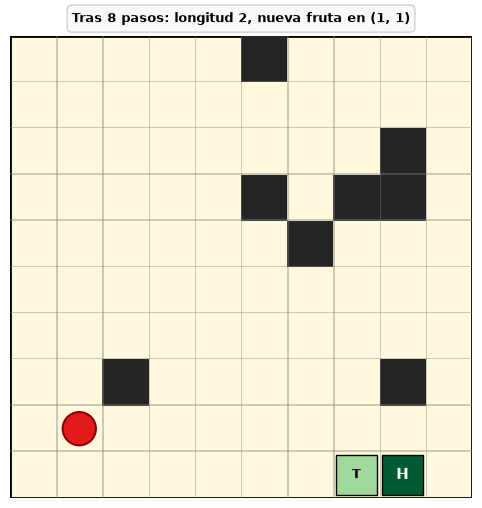

In [5]:
# step() a mano: se sigue el plan de A* y se registra (s', R, done) en cada turno
plan = solucion(a_estrella(SubproblemaSnake(estado_inicial=s, lambda_riesgo=0.5), heuristica_manhattan))

filas = []
for t, accion in enumerate(plan, start=1):
    s, R, done = env_demo.step(accion)
    filas.append({
        "t": t, "acción": accion, "cabeza c1": s.cabeza, "longitud L": s.longitud,
        "R(s,a,s')": round(R, 3), "done": done, "frutas_comidas": env_demo.frutas_comidas,
        "ganancia_total": env_demo.ganancia_total, "perdida_total": round(env_demo.perdida_total, 3),
        "causa_fin": env_demo.causa_fin,
    })
tabla_step = pd.DataFrame(filas).set_index("t")
display(tabla_step)
G = tabla_step["R(s,a,s')"].sum()
print(f"Recompensa acumulada G = ΣR = {G:.3f} = ganancia_total - perdida_total = "
      f"{env_demo.ganancia_total:.3f} - {env_demo.perdida_total:.3f}")

# Acción no aplicable: el entorno la trata como colisión (derrota) y termina el episodio
from copy import deepcopy
env_choque = deepcopy(env_demo)
invalidas = [a for a in ["norte", "sur", "este", "oeste"] if a not in env_choque.acciones_aplicables()]
s_choque, R_choque, done_choque = env_choque.step(invalidas[0])
print(f"\nstep('{invalidas[0]}') no aplicable -> R = {R_choque}, done = {done_choque}, causa_fin = '{env_choque.causa_fin}'")

env_demo.render(titulo=f"Tras {env_demo.pasos} pasos: longitud {s.longitud}, nueva fruta en {s.fruta}")
plt.show()

### 3.2 Los 6 algoritmos de búsqueda sobre la misma instancia
Se aplican directamente las seis funciones de `busqueda.py` (`anchura`, `profundidad`, `dijkstra`, `avara`, `a_estrella` y `busqueda_haz`) sobre `prob_ejemplo`, dibujando el camino que encuentra cada una (verde) y los nodos que expandió (azul). La tabla posterior, generada con `comparar_algoritmos_en_instancia`, reúne las métricas de los 6 algoritmos con cada heurística aplicable y marca si la solución alcanza el costo óptimo.

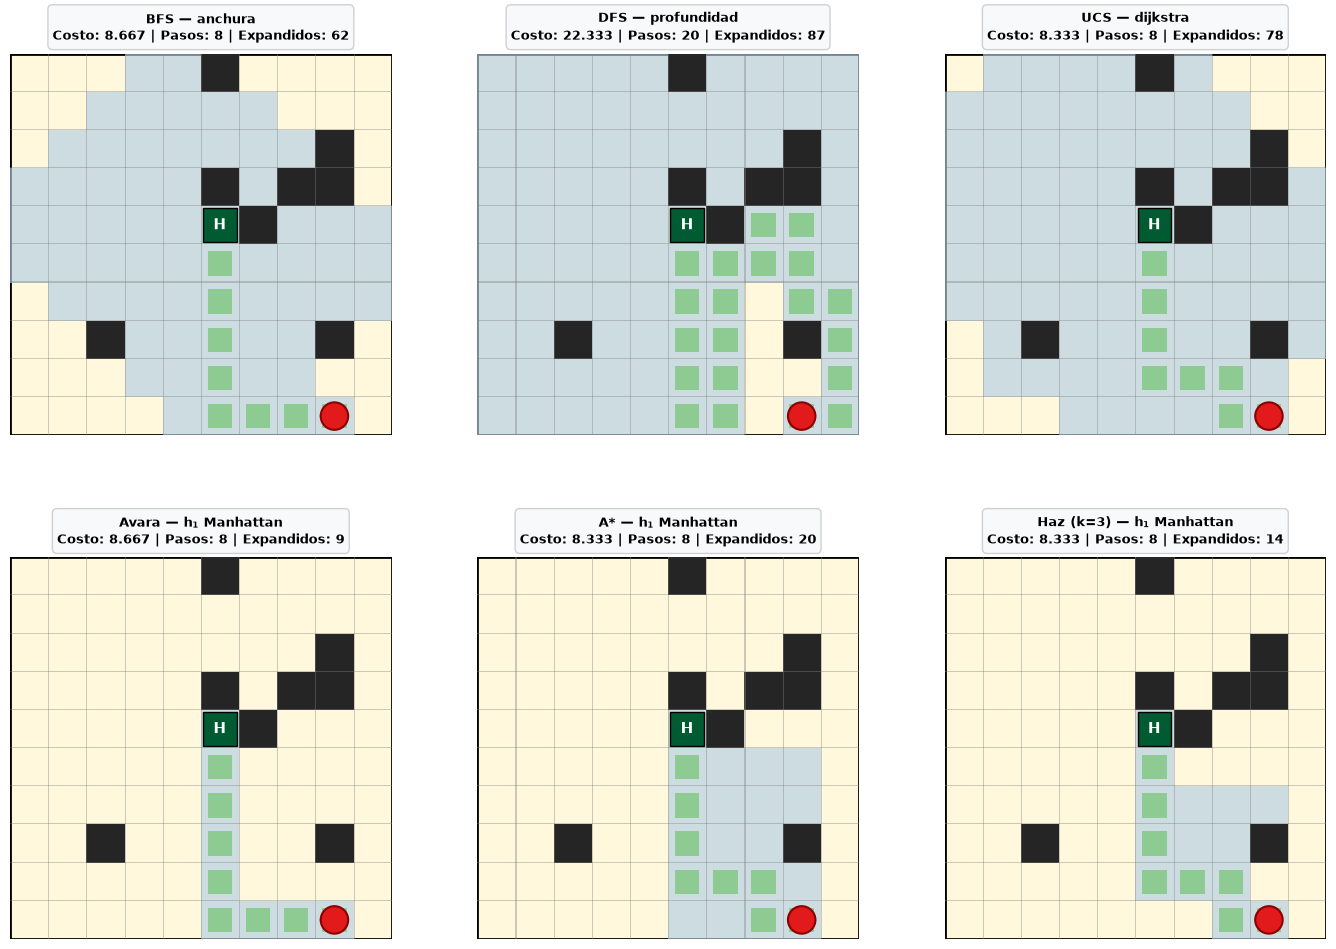

,Algoritmo,Heurística,Éxito,Costo g,Pasos,Nodos generados,Nodos expandidos,Frontera máx.,Tiempo (ms),¿Óptimo?
0,BFS,ninguna,True,8.667,8,75,62,18,2.981,False
1,DFS,ninguna,True,22.333,20,146,87,61,3.933,False
2,UCS,ninguna,True,8.333,8,87,78,21,2.929,True
3,Avara,manhattan,True,8.667,8,20,9,12,0.511,False
4,Avara,euclidea,True,8.333,8,19,9,11,0.440,True
5,Avara,riesgo,True,8.333,8,21,9,13,0.524,True
6,A*,manhattan,True,8.333,8,33,20,14,0.948,True
7,A*,euclidea,True,8.333,8,35,23,13,1.155,True
8,A*,riesgo,True,8.333,8,32,20,15,1.024,True
9,Beam(k=3),manhattan,True,8.333,8,27,14,3,0.681,True


In [6]:
# Aplicación directa de los 6 algoritmos y dibujo de sus caminos
algoritmos = [
    ("BFS — anchura",          lambda p: anchura(p, guardar_traza=True)),
    ("DFS — profundidad",      lambda p: profundidad(p, guardar_traza=True)),
    ("UCS — dijkstra",         lambda p: dijkstra(p, guardar_traza=True)),
    ("Avara — h₁ Manhattan",   lambda p: avara(p, heuristica_manhattan, guardar_traza=True)),
    ("A* — h₁ Manhattan",      lambda p: a_estrella(p, heuristica_manhattan, guardar_traza=True)),
    ("Haz (k=3) — h₁ Manhattan", lambda p: busqueda_haz(p, heuristica_manhattan, k=3, guardar_traza=True)),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 11.5), gridspec_kw={"hspace": 0.32, "wspace": 0.22})
for ax, (nombre, algoritmo) in zip(axes.flat, algoritmos):
    prob = SubproblemaSnake(estado_inicial=est_ejemplo, lambda_riesgo=0.5)
    nodo = algoritmo(prob)
    r = prob.ultimo_resultado
    expandidos = r.traza[-1].expandidos_celdas if r.traza else None
    env_ejemplo.render(
        estado=est_ejemplo, camino=r.camino_celdas, expandidos=expandidos, ax=ax,
        titulo=(f"{nombre}\nCosto: {r.costo_total:.3f} | Pasos: {len(solucion(nodo))} | "
                f"Expandidos: {r.nodos_expandidos}"),
    )
plt.show()

# Tabla de métricas de los 6 algoritmos (y heurísticas) sobre la misma instancia
resultados = comparar_algoritmos_en_instancia(est_ejemplo, lambda_riesgo=0.5)
tabla_algoritmos = pd.DataFrame([{
    "Algoritmo": r.algoritmo, "Heurística": r.heuristica, "Éxito": r.exito,
    "Costo g": round(r.costo_total, 3), "Pasos": r.longitud_solucion,
    "Nodos generados": r.nodos_generados, "Nodos expandidos": r.nodos_expandidos,
    "Frontera máx.": r.max_frontera, "Tiempo (ms)": round(r.tiempo_ms, 3), "¿Óptimo?": r.es_optimo,
} for r in resultados])
display(tabla_algoritmos)

### 3.3 Comparación de las heurísticas $h_1$, $h_2$ y $h_3$
Las tres heurísticas de `busqueda.py` son $h_1$ = distancia Manhattan, $h_2$ = distancia euclídea y $h_3$ = Manhattan más una penalización por el riesgo de encierro alrededor de la cabeza. Como cada paso cuesta $c(s,a,s') \ge 1$, $h_1$ y $h_2$ nunca sobreestiman la pérdida real hasta la fruta (son **admisibles**), mientras que $h_3$ puede sobreestimarla. Para comprobarlo, se comparan sus valores con el costo óptimo real $h^*(s)$, calculado con `dijkstra`, en los estados que visita una partida, y se mide cuántos nodos expande `A*` con cada una.

,estados,h_promedio,h_estrella_promedio,pct_admisible,nodos_expandidos_A,pct_A_optimo
Heurística,,,,,,
h₁ Manhattan,30,5.23,5.6,100.00,10.90,100.0
h₂ Euclídea,30,4.31,5.6,100.00,12.23,100.0
h₃ Riesgo,30,5.46,5.6,73.33,10.80,100.0


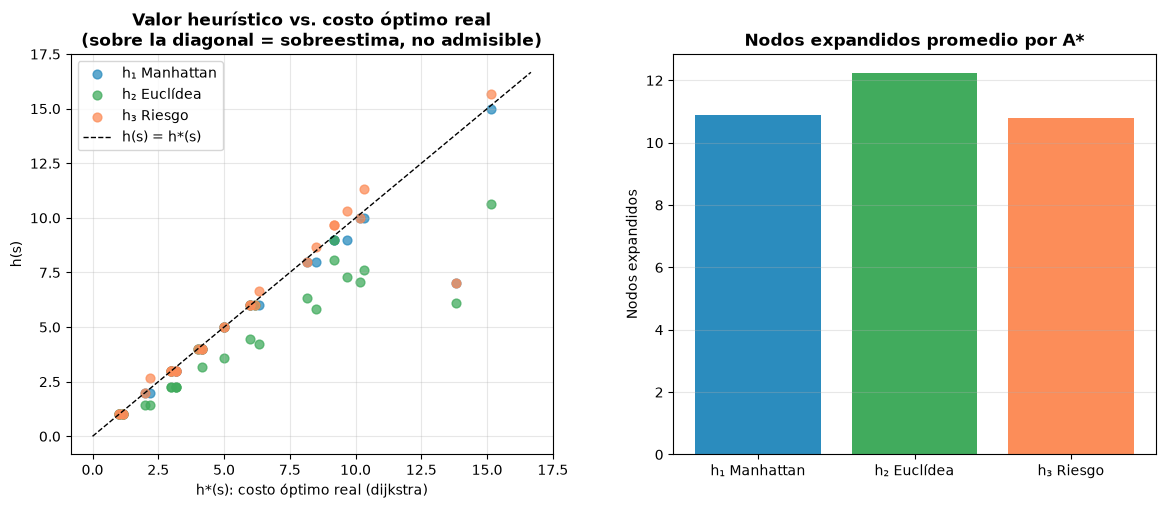

In [7]:
# Admisibilidad empírica: h(s) <= h*(s) en los estados de una partida real
heuristicas = {"h₁ Manhattan": heuristica_manhattan, "h₂ Euclídea": heuristica_euclidea, "h₃ Riesgo": heuristica_riesgo}

env_h = Snake(tamano=10, semilla=1, k_max=200, lambda_riesgo=0.5)
ag_h = AgenteSnake(algoritmo="A*", heuristica="manhattan", chequeo_seguridad=True, lambda_riesgo=0.5)
s_h = env_h.reset(semilla=1)
ag_h.states.append(s_h)
estados_muestra = []
while not env_h.done and len(estados_muestra) < 150:
    if s_h.fruta is not None:
        estados_muestra.append(s_h)
    s_h, _, _ = env_h.step(ag_h.make_decision())
    ag_h.states.append(s_h)
estados_muestra = estados_muestra[::5]

filas = []
for s_i in estados_muestra:
    prob = SubproblemaSnake(estado_inicial=s_i, lambda_riesgo=0.5)
    if dijkstra(prob) is None:
        continue
    h_estrella = prob.ultimo_resultado.costo_total
    for nombre, fn_h in heuristicas.items():
        prob_a = SubproblemaSnake(estado_inicial=s_i, lambda_riesgo=0.5)
        a_estrella(prob_a, fn_h)
        r = prob_a.ultimo_resultado
        filas.append({"Heurística": nombre, "h(s)": fn_h(s_i), "h*(s)": h_estrella,
                      "Admisible en s": fn_h(s_i) <= h_estrella + 1e-9,
                      "Nodos expandidos A*": r.nodos_expandidos,
                      "Costo A*": r.costo_total, "A* óptimo": abs(r.costo_total - h_estrella) < 1e-6})
df_h = pd.DataFrame(filas)

resumen_h = df_h.groupby("Heurística").agg(
    estados=("h(s)", "size"),
    h_promedio=("h(s)", "mean"),
    h_estrella_promedio=("h*(s)", "mean"),
    pct_admisible=("Admisible en s", lambda x: 100 * x.mean()),
    nodos_expandidos_A=("Nodos expandidos A*", "mean"),
    pct_A_optimo=("A* óptimo", lambda x: 100 * x.mean()),
).round(2)
display(resumen_h)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"wspace": 0.25})
colores = {"h₁ Manhattan": "#2b8cbe", "h₂ Euclídea": "#41ab5d", "h₃ Riesgo": "#fc8d59"}
lim = max(df_h["h(s)"].max(), df_h["h*(s)"].max()) + 1
for nombre, grupo in df_h.groupby("Heurística"):
    axes[0].scatter(grupo["h*(s)"], grupo["h(s)"], label=nombre, color=colores[nombre], alpha=0.75, s=40)
axes[0].plot([0, lim], [0, lim], "k--", lw=1, label="h(s) = h*(s)")
axes[0].set_title("Valor heurístico vs. costo óptimo real\n(sobre la diagonal = sobreestima, no admisible)", weight="bold")
axes[0].set_xlabel("h*(s): costo óptimo real (dijkstra)")
axes[0].set_ylabel("h(s)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(resumen_h.index, resumen_h["nodos_expandidos_A"], color=[colores[n] for n in resumen_h.index])
axes[1].set_title("Nodos expandidos promedio por A*", weight="bold")
axes[1].set_ylabel("Nodos expandidos")
axes[1].grid(axis="y", alpha=0.3)
plt.show()

---
## 4. Demostración del Chequeo de Seguridad (Camino hacia la Cola $c_L$)
Comparación sobre la **misma semilla (Semilla 0)** entre un agente `A*` que solo persigue la fruta por el camino más corto (**Sin Chequeo de Seguridad**) y nuestro agente completo que verifica mediante búsqueda en grafo si tras comer la fruta persiste un camino hacia su propia cola $c_L$ (**Con Chequeo de Seguridad**).


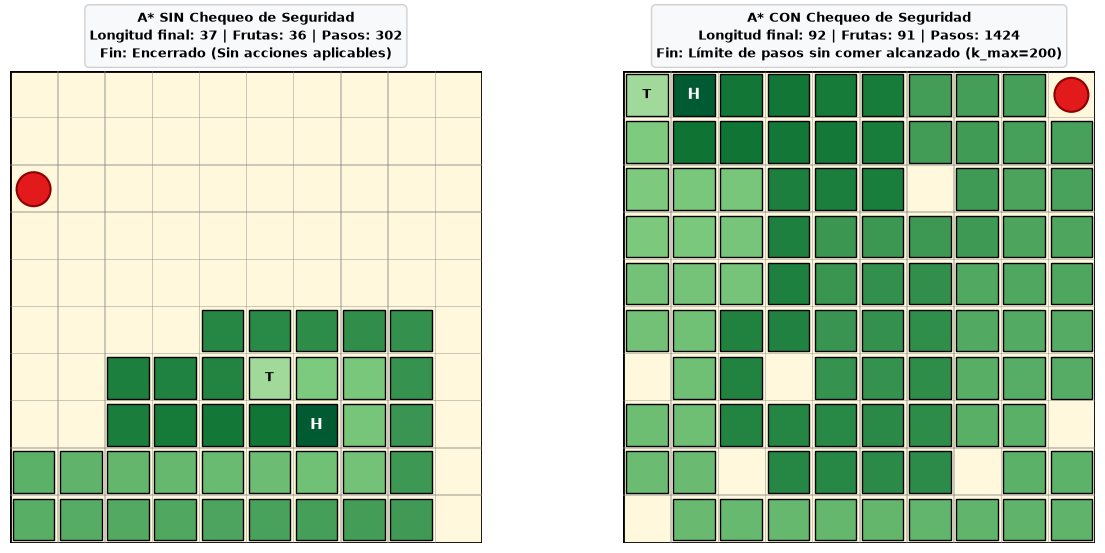

In [8]:
# Impacto del Chequeo de Seguridad en la supervivencia de la serpiente
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={'wspace': 0.30})

for idx, usar_seguridad in enumerate([False, True]):
    env_c = Snake(tamano=10, semilla=0, k_max=200)
    ag_c = AgenteSnake(algoritmo="A*", heuristica="manhattan", chequeo_seguridad=usar_seguridad)
    est = env_c.reset(semilla=0)
    ag_c.states.append(est)

    while not env_c.done and env_c.pasos < 3000:
        acc = ag_c.make_decision()
        est, rew, done = env_c.step(acc)
        ag_c.states.append(est)

    etiqueta = "CON Chequeo de Seguridad" if usar_seguridad else "SIN Chequeo de Seguridad"
    titulo = (
        f"A* {etiqueta}\n"
        f"Longitud final: {env_c.estado.longitud} | Frutas: {env_c.frutas_comidas} | Pasos: {env_c.pasos}\n"
        f"Fin: {env_c.causa_fin}"
    )
    env_c.render(titulo=titulo, ax=axes[idx])

plt.show()


---
## 5. Evaluación Experimental en 100 Partidas Reproducibles (Semillas $0, \dots, 99$)
Se evalúan los 6 algoritmos con y sin chequeo de seguridad, así como el efecto de las heurísticas ($h_1$ Manhattan vs. $h_2$ Euclídea) y del costo de riesgo ($\lambda = 0.5$), registrando todas las métricas en `resultados_benchmark_100_semillas.csv`.


,algoritmo,heuristica,chequeo_seguridad,lambda_riesgo,Longitud_Prom,Longitud_Std,Longitud_Max,Victorias_Pct,Pasos_por_Fruta,Nodos_Gen_Prom,Nodos_Exp_Prom,Max_Frontera,Tiempo_Dec_ms,Recompensa_Prom
0,A*,euclidea,True,0.0,93.07,7.57,100,3.0,20.78,53.58,47.21,24.81,1.90,7212.32
1,A*,manhattan,False,0.0,34.85,9.05,59,0.0,8.09,29.19,20.65,22.34,0.97,3006.42
2,A*,manhattan,True,0.0,93.29,8.51,100,2.0,20.30,54.63,47.94,22.67,1.89,7258.23
3,A*,manhattan,True,0.5,91.05,7.22,100,2.0,20.73,54.59,46.87,26.55,2.71,6684.11
4,Avara,manhattan,False,0.0,34.13,8.62,58,0.0,8.19,21.75,12.84,23.43,0.97,2936.69
5,Avara,manhattan,True,0.0,93.51,9.40,100,7.0,19.99,52.04,43.80,24.13,1.73,7353.25
6,BFS,ninguna,False,0.0,34.17,8.31,55,0.0,8.00,44.35,37.42,18.11,0.88,2948.29
7,BFS,ninguna,True,0.0,91.54,12.06,100,8.0,19.09,57.30,50.65,18.28,1.09,7275.24
8,Beam,manhattan,False,0.0,34.73,9.69,65,0.0,8.25,26.11,16.09,6.99,0.71,2988.03
9,Beam,manhattan,True,0.0,92.26,8.79,100,1.0,20.10,51.05,42.31,16.47,1.62,7184.45


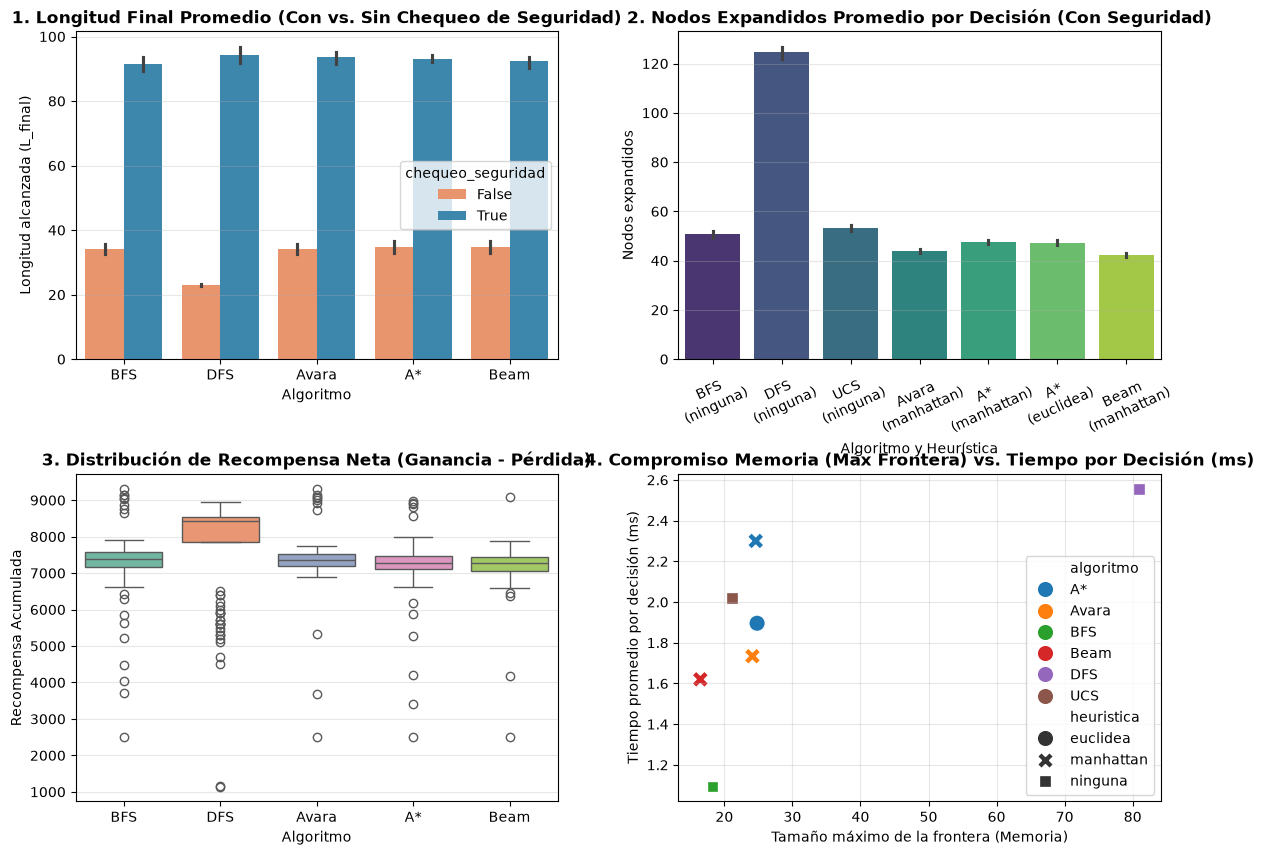

In [9]:
# Ejecución (o carga desde caché CSV) del experimento de las 100 semillas
# RECALCULAR_BENCHMARK = True vuelve a jugar las 100 partidas de cada configuración;
# con False se cargan los resultados guardados en el CSV.
RECALCULAR_BENCHMARK = False

ruta_csv = str(CARPETA / "resultados_benchmark_100_semillas.csv")
df_crudo, df_resumen = ejecutar_benchmark_completo(
    num_semillas=100,
    tamano=10,
    k_max=200,
    archivo_csv=ruta_csv,
    forzar_recalculo=RECALCULAR_BENCHMARK,
)

display(df_resumen)
graficar_resultados_benchmark(df_crudo)

---
## 6. Variantes de Complejidad Creciente (Sección 5 de la Propuesta)
1. **Tablero Toroidal (sin bordes):** La distancia Manhattan clásica deja de ser admisible y el agente emplea la distancia Manhattan toroidal $\min(|\Delta x|, N-|\Delta x|) + \min(|\Delta y|, N-|\Delta y|)$.
2. **Múltiples frutas simultáneas (3 frutas) + Obstáculos fijos:** El agente toma $h(s) = \min_{i} d(c_1, f_i)$ sorteando muros estáticos en un tablero $12 \times 12$.
3. **Fruta Adversaria (Minimax con Poda Alfa-Beta):** Un segundo jugador (`AgenteFrutaAdversaria`) coloca cada nueva fruta en la celda libre que minimiza la utilidad esperada de la serpiente.


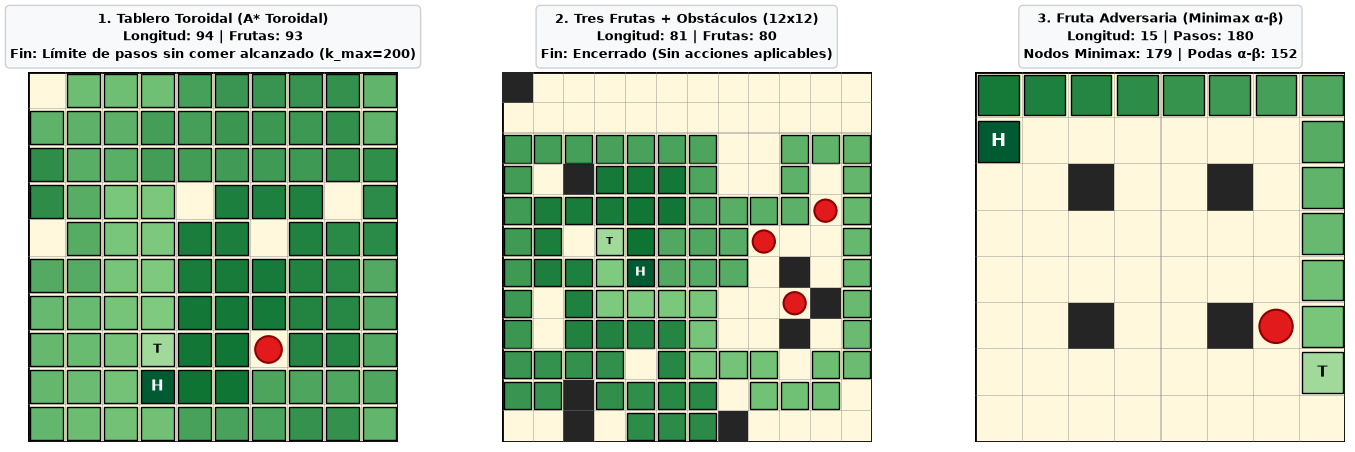

In [10]:
# Ejecución y visualización de las 3 variantes propuestas
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), gridspec_kw={'wspace': 0.28})

# 1. Variante Toroidal
env_toro = Snake(tamano=10, semilla=5, toroidal=True, k_max=200)
ag_toro = AgenteSnake(algoritmo="A*", heuristica="manhattan", chequeo_seguridad=True)
est = env_toro.reset(semilla=5)
ag_toro.states.append(est)
while not env_toro.done and env_toro.pasos < 2500:
    est, _, _ = env_toro.step(ag_toro.make_decision())
    ag_toro.states.append(est)
env_toro.render(
    titulo=f"1. Tablero Toroidal (A* Toroidal)\nLongitud: {env_toro.estado.longitud} | Frutas: {env_toro.frutas_comidas}\nFin: {env_toro.causa_fin}",
    ax=axes[0],
)

# 2. Variante 3 Frutas Simultáneas + Obstáculos Fijos
env_m = Snake(tamano=12, semilla=3, num_obstaculos=8, num_frutas=3, k_max=200)
ag_m = AgenteSnake(algoritmo="A*", heuristica="manhattan", chequeo_seguridad=True, lambda_riesgo=0.5)
est = env_m.reset(semilla=3)
ag_m.states.append(est)
while not env_m.done and env_m.pasos < 2500:
    est, _, _ = env_m.step(ag_m.make_decision())
    ag_m.states.append(est)
env_m.render(
    titulo=f"2. Tres Frutas + Obstáculos (12x12)\nLongitud: {env_m.estado.longitud} | Frutas: {env_m.frutas_comidas}\nFin: {env_m.causa_fin}",
    ax=axes[1],
)

# 3. Variante Fruta Adversaria (Minimax con Poda Alfa-Beta)
juego_adv = SnakeJuegoAdversario(tamano=8, obstaculos=((2, 2), (5, 5), (2, 5), (5, 2)))
oponente = AgenteFrutaAdversaria(game=juego_adv, jugador='fruta', max_lim=2)
env_adv = EnvfromGameAndPl2(juego_adv, oponente)
ag_s = AgenteSnake(algoritmo="A*", heuristica="manhattan", chequeo_seguridad=True)

est_a = env_adv.reset()
ag_s.states.append(est_a)
pasos_a = 0
while not juego_adv.es_terminal(env_adv.state) and pasos_a < 180:
    est_a, _, _ = env_adv.step(ag_s.make_decision())
    ag_s.states.append(est_a)
    pasos_a += 1

env_adv.render(
    ax=axes[2],
    titulo=(
        f"3. Fruta Adversaria (Minimax α-β)\n"
        f"Longitud: {env_adv.state.longitud} | Pasos: {pasos_a}\n"
        f"Nodos Minimax: {oponente.nodos_evaluados_minimax} | Podas α-β: {oponente.podas_alfa_beta}"
    ),
)
plt.show()